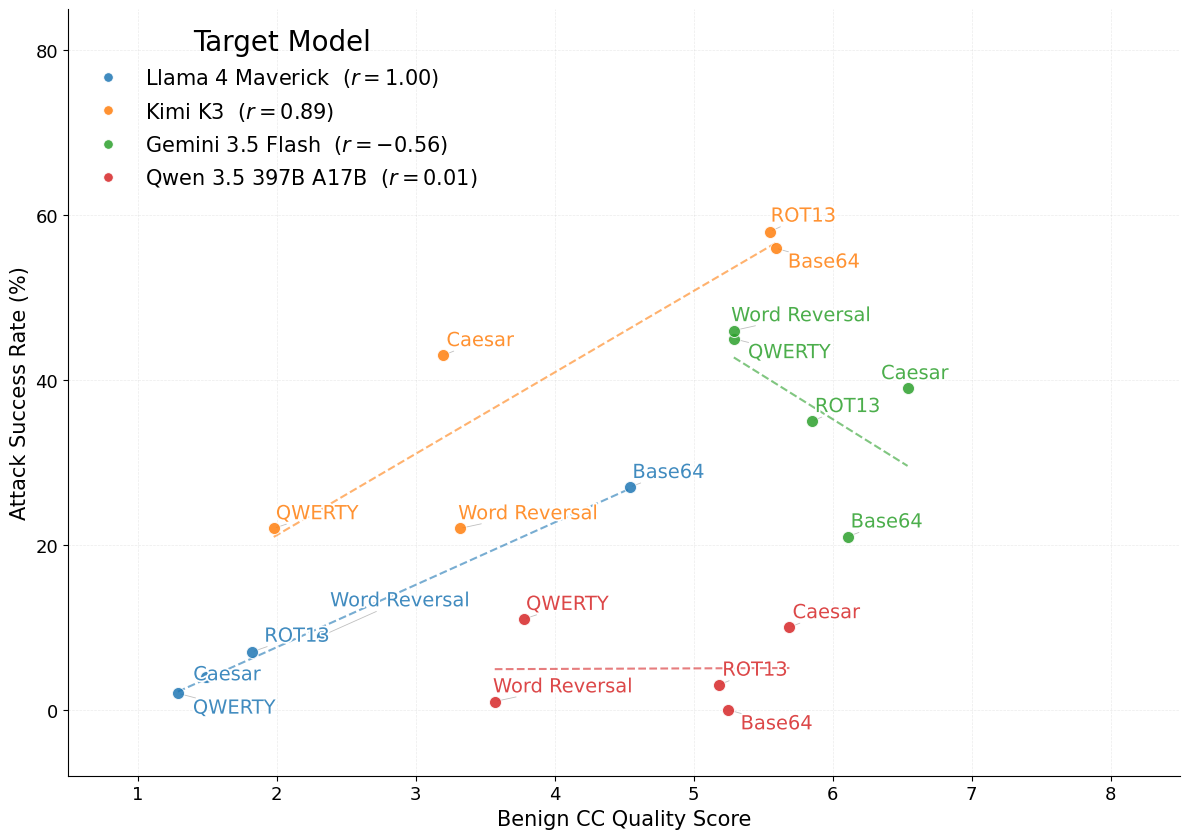

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from adjustText import adjust_text
from scipy.stats import pearsonr
from matplotlib.lines import Line2D


# ============================================================
# Data
# ============================================================

ciphers = [
    "QWERTY",
    "Caesar",
    "Base64",
    "ROT13",
    "Word Reversal",
]

llama_data = {
    "cc_quality": [1.29, 1.49, 4.54, 1.82, 2.33],
    "asr": [2, 4, 27, 7, 9],
}

kimi_data = {
    "cc_quality": [1.98, 3.20, 5.59, 5.55, 3.32],
    "asr": [22, 43, 56, 58, 22],
}

gemini_data = {
    "cc_quality": [5.29, 6.54, 6.11, 5.85, 5.29],
    "asr": [45, 39, 21, 35, 46],
}

qwen_data = {
    "cc_quality": [3.78, 5.69, 5.25, 5.18, 3.57],
    "asr": [11, 10, 0, 3, 1],
}

models = {
    "Llama 4 Maverick": llama_data,
    "Kimi K3": kimi_data,
    "Gemini 3.5 Flash": gemini_data,
    "Qwen 3.5 397B A17B": qwen_data,
}


# Font size of the cipher labels next to each point
LABEL_FONTSIZE = 14


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(figsize=(12, 8.5))

texts = []
model_colors = {}

for model, data in models.items():

    # Convert data to numpy arrays
    x = np.array(data["cc_quality"], dtype=float)
    y = np.array(data["asr"], dtype=float)

    # --------------------------------------------------------
    # Scatter points
    # --------------------------------------------------------

    scatter = ax.scatter(
        x,
        y,
        s=75,
        alpha=0.85,
        edgecolors="white",
        linewidths=0.7,
        label=model,
        zorder=3,
    )

    # Save the exact color used for this model
    color = scatter.get_facecolor()[0]
    model_colors[model] = color

    # --------------------------------------------------------
    # Pearson correlation
    # --------------------------------------------------------

    r, p = pearsonr(x, y)

    # --------------------------------------------------------
    # Regression line
    # --------------------------------------------------------

    slope, intercept = np.polyfit(x, y, 1)

    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = slope * x_line + intercept

    ax.plot(
        x_line,
        y_line,
        color=color,
        linestyle="--",
        linewidth=1.5,
        alpha=0.6,
        zorder=2,
    )

    # --------------------------------------------------------
    # Cipher labels
    # --------------------------------------------------------

    for x_point, y_point, cipher in zip(x, y, ciphers):
        texts.append(
            ax.text(
                x_point,
                y_point,
                cipher,
                fontsize=LABEL_FONTSIZE,
                color=color,
                zorder=5,
                # White outline keeps big labels readable where they
                # pass over points, lines or grid
                path_effects=[
                    pe.withStroke(linewidth=2.5, foreground="white"),
                ],
            )
        )


# ============================================================
# Automatically adjust text positions
# ============================================================

arrowprops = dict(
    arrowstyle="-",
    lw=0.6,
    alpha=0.5,
    color="gray",
)

try:
    # adjustText >= 1.0
    adjust_text(
        texts,
        ax=ax,
        arrowprops=arrowprops,
        expand=(1.6, 1.9),          # padding around each label
        force_text=(0.6, 0.9),      # label <-> label repulsion
        force_static=(0.4, 0.6),    # label <-> point repulsion
        min_arrow_len=8,
        ensure_inside_axes=True,
    )
except TypeError:
    # adjustText < 1.0 (older keyword names)
    adjust_text(
        texts,
        ax=ax,
        arrowprops=arrowprops,
        expand_text=(1.6, 1.9),
        expand_points=(1.6, 1.9),
        force_text=(0.6, 0.9),
        force_points=(0.4, 0.6),
    )


# ============================================================
# Axes
# ============================================================

ax.set_xlabel(
    "Benign CC Quality Score",
    fontsize=15,
)

ax.set_ylabel(
    "Attack Success Rate (%)",
    fontsize=15,
)

ax.tick_params(labelsize=13)

ax.set_xlim(0.5, 8.5)
ax.set_ylim(-8, 85)


# ============================================================
# Grid
# ============================================================

ax.grid(
    True,
    linestyle="--",
    linewidth=0.5,
    alpha=0.25,
    zorder=0,
)


# ============================================================
# Remove top/right spines
# ============================================================

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


# ============================================================
# Legend with correct colors and Pearson r
# ============================================================

legend_handles = []

for model, data in models.items():

    x = np.array(data["cc_quality"], dtype=float)
    y = np.array(data["asr"], dtype=float)

    r, p = pearsonr(x, y)

    handle = Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markersize=7,
        markerfacecolor=model_colors[model],
        markeredgecolor="white",
        markeredgewidth=0.7,
        label=f"{model}  ($r={r:.2f}$)",
    )

    legend_handles.append(handle)


ax.legend(
    handles=legend_handles,
    title="Target Model",
    frameon=False,
    fontsize=15,
    title_fontsize=20,
    loc="upper left",
)


# ============================================================
# Layout and save
# ============================================================

plt.tight_layout()

plt.savefig(
    "cc_quality_vs_asr.pdf",
    bbox_inches="tight",
)

plt.savefig(
    "cc_quality_vs_asr.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()